
[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Shape: (186553, 19)
Train shape: (149242, 18) Test shape: (37311, 18)

Model Comparison:
           Model  Accuracy  Precision  Recall  F1-Score
0    Naive Bayes     0.586      0.495   0.263     0.344
1  Decision Tree     0.813      0.747   0.827     0.785
2            SVM     0.535      0.456   0.659     0.539


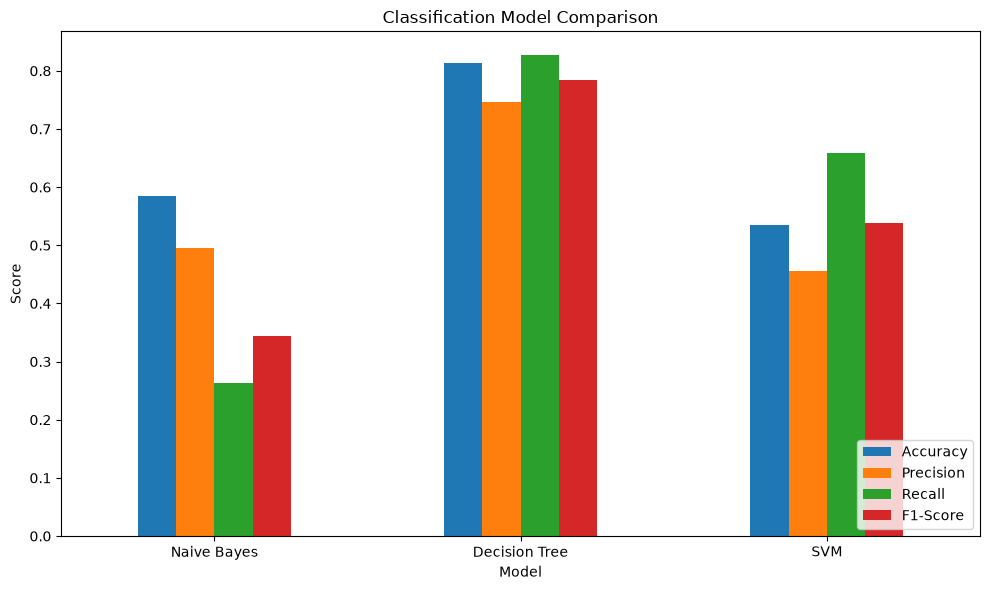

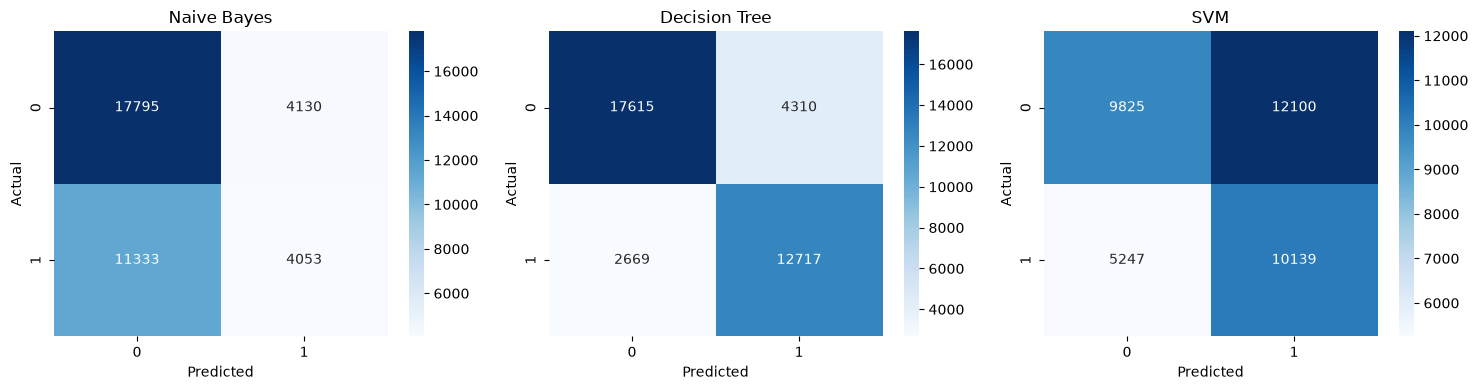


Results saved to data/processed/classification_results.csv
Saved Decision Tree model (best performer) and feature columns
                               Feature  Importance
1                            Start_Lng    0.611342
0                            Start_Lat    0.378311
7                                 Hour    0.005108
3                          Humidity(%)    0.001921
2                       Temperature(F)    0.001182
5                      Wind_Speed(mph)    0.000690
4                       Visibility(mi)    0.000300
14          Weather_Condition_Overcast    0.000212
10        Weather_Condition_Light Rain    0.000209
12     Weather_Condition_Mostly Cloudy    0.000183
6                       Sunrise_Sunset    0.000148
15     Weather_Condition_Partly Cloudy    0.000133
13             Weather_Condition_Other    0.000120
9               Weather_Condition_Haze    0.000051
17  Weather_Condition_Scattered Clouds    0.000045
16              Weather_Condition_Rain    0.000029
11        

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
%pip install seaborn

import seaborn as sns

nb = GaussianNB()


df = pd.read_csv('../data/processed/accidents_cleaned.csv')
print("Shape:", df.shape)



X = df.drop(columns=['Severity_Binary', 'Start_Lat', 'Start_Lng'])
y = df['Severity_Binary']

print("Training with features:", X.columns.tolist())
assert 'Start_Lat' not in X.columns, "Start_Lat still present!"
assert 'Start_Lng' not in X.columns, "Start_Lng still present!"
print("✓ Lat/Lng successfully excluded")


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)


nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)


dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)



X_train_svm, _, y_train_svm, _ = train_test_split(
    X_train, y_train,
    train_size=min(20000, len(X_train)),
    stratify=y_train,
    random_state=42
)

svm = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm.fit(X_train_svm, y_train_svm)
svm_pred = svm.predict(X_test)

def evaluate(name, y_true, y_pred):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

results = pd.DataFrame([
    evaluate('Naive Bayes', y_test, nb_pred),
    evaluate('Decision Tree', y_test, dt_pred),
    evaluate('SVM', y_test, svm_pred)
])

print("\nModel Comparison:")
print(results.round(3))


results.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(
    kind='bar', figsize=(10, 6)
)
plt.title('Classification Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, [('Naive Bayes', nb_pred), ('Decision Tree', dt_pred), ('SVM', svm_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()


results.to_csv('../data/processed/classification_results.csv', index=False)
print("\nResults saved to data/processed/classification_results.csv")

import joblib
joblib.dump(dt, '../app/models/decision_tree_model.pkl')
joblib.dump(X_train.columns.tolist(), '../app/models/feature_columns.pkl')
print("Saved Decision Tree model (best performer) and feature columns")

import pandas as pd

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': dt.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance_df.to_string())

import os
print("Notebook's current working directory:", os.getcwd())
print("Absolute save path:", os.path.abspath('../app/models/feature_columns.pkl'))

# Read back what was just saved, immediately, in the same session
import joblib
check = joblib.load('../app/models/feature_columns.pkl')
print("\nJust-saved feature_columns.pkl contains:", check)
print("Start_Lat present?", 'Start_Lat' in check)
print("Start_Lng present?", 'Start_Lng' in check)